In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
import lifetimes
print("All libraries imported successfully!")
print("Customer Lifetime Value Prediction Project Started!")

All libraries imported successfully!
Customer Lifetime Value Prediction Project Started!


In [13]:
from pathlib import Path
# Set project directory
PROJECT_DIR = Path.home()/"Documents"/"CLV_Project"
# Set data directory
DATA_DIR = PROJECT_DIR/"data"
# Create output folders if needed
for folder in["data","notebooks","src","models","outputs"]:
    (PROJECT_DIR /folder).mkdir(parents=True,
exist_ok = True)

print("Project folder:",PROJECT_DIR)
print("Data folder:",DATA_DIR)
print("Folder setup completed successfully!")

Project folder: /Users/kajalverma/Documents/CLV_Project
Data folder: /Users/kajalverma/Documents/CLV_Project/data
Folder setup completed successfully!


In [14]:
# Check files inside data folder
import os
print("Files available in data folder:")
for file in os.listdir(DATA_DIR):
    print(file)

Files available in data folder:
Online Retail.xlsx


In [15]:
# Load Online Retail Dataset
file_path = DATA_DIR/"Online Retail.xlsx"
df= pd.read_excel(file_path)
print("Dataset loaded successfully!")
print("Dataset Shape:",df.shape)

# Display first 5 rows 
df.head()

Dataset loaded successfully!
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [16]:
# Dataset information
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [17]:
# Statistical summary
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [18]:
print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [19]:
# Check missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [20]:
# Check duplicate records
print("Total Duplicate Rows:",df.duplicated().sum())

Total Duplicate Rows: 5268


In [21]:
# Check column data types
print(df.dtypes)

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [22]:
# Check negative quality and price

print("Negative Quantity:",
      (df["Quantity"]<0).sum())
print("Zero or Negative Price:",
      (df["UnitPrice"]<=0).sum())

Negative Quantity: 10624
Zero or Negative Price: 2517


In [23]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [24]:
# Remove duplicate records
df = df.drop_duplicates()
# remove missing CustomerID
df = df.dropna(subset=['CustomerID'])
# Remove cancelled invoices
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
# remove negative and zero quantity
df = df[df['Quantity']>0]
# Remove zero and negative prices
df = df[df['UnitPrice']>0]
# Calculate total purchase amount
df['TotalAmount'] = df['Quantity']*df['UnitPrice']
# Reset index
df = df.reset_index(drop=True)
print("Data Cleaning Completed Successfully!")
print("Cleaned Dataset Shape:",df.shape)
df.head()

Data Cleaning Completed Successfully!
Cleaned Dataset Shape: (392692, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [25]:
print("Missing CustomerID:",df['CustomerID'].isnull().sum())
print("Duplicate Rows:",df.duplicated().sum())
print("Negative Quantity:",(df['Quantity']<0).sum())
print("Zero or Negative Price:",(df['UnitPrice']<=0).sum())

Missing CustomerID: 0
Duplicate Rows: 0
Negative Quantity: 0
Zero or Negative Price: 0


In [26]:
import pandas as pd
#Set analysis date 
snapshot_date = df['InvoiceDate'].max()+pd.Timedelta(days=1)


# Calculate RFM values
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate':lambda x: (snapshot_date -x.max()).days,
    'InvoiceNo':'nunique',
    'TotalAmount':'sum'
})
# Rename columns 
rfm.columns = ['Recency','Frequency','Monetary']

# Display RFM table
print("RFM Analysis Completed Successfully!")
print("RFM Dataset Shape:",rfm.shape)
rfm.head()

RFM Analysis Completed Successfully!
RFM Dataset Shape: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [27]:
# Calculate RFM Scores 
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    4,
    labels=[4,3,2,1]
)
rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    4,
    labels=[1,2,3,4]
)
rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    4,
    labels=[1,2,3,4]
)
# Claculate total RFM score
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(int)+
    rfm['F_Score'].astype(int)+
    rfm['M_Score'].astype(int)
)

print("RFM Scoring Completed!")
rfm.head()

RFM Scoring Completed!


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,4,6
12347.0,2,7,4310.00,4,4,4,12
12348.0,75,4,1797.24,2,3,4,9
12349.0,19,1,1757.55,3,1,4,8
12350.0,310,1,334.40,1,1,2,4


In [28]:
# Customer Segmentation

def segment_customer(score):
    if score >= 10:
        return 'VIP Customer'
    elif score >= 7:
        return 'Regular Customer'
    elif score >= 5:
        return 'Potential Customer'
    else:
        return 'Low Value Customer'

# Assign customer segments
rfm['Customer_Segment'] = rfm['RFM_Score'].apply(segment_customer)

# Display customer segments
print("Customer Segmentation Completed!")
print(rfm[['Recency', 'Frequency', 'Monetary',
           'RFM_Score', 'Customer_Segment']].head(10))

# Count customers in each segment
print("\nSegment Summary:")
print(rfm['Customer_Segment'].value_counts())

Customer Segmentation Completed!
            Recency  Frequency  Monetary  RFM_Score    Customer_Segment
CustomerID                                                             
12346.0         326          1  77183.60          6  Potential Customer
12347.0           2          7   4310.00         12        VIP Customer
12348.0          75          4   1797.24          9    Regular Customer
12349.0          19          1   1757.55          8    Regular Customer
12350.0         310          1    334.40          4  Low Value Customer
12352.0          36          8   2506.04         11        VIP Customer
12353.0         204          1     89.00          3  Low Value Customer
12354.0         232          1   1079.40          5  Potential Customer
12355.0         214          1    459.40          4  Low Value Customer
12356.0          23          3   2811.43         10        VIP Customer

Segment Summary:
Customer_Segment
Regular Customer      1271
VIP Customer          1260
Potential Cust

In [29]:
# CLV Prediction using Machine Learning

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np 

# Prepare features and target
X = rfm[['Recency','Frequency']]
y = rfm['Monetary']
 # split dataset
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)
#TRain model
model = RandomForestRegressor(
    n_estimators=100,random_state=42
)
model.fit(X_train,y_train)

# Make predictions
y_pred = model.predict(X_test)


# Evaluate model
print("Model Training Completed!")
print("MAE:",mean_absolute_error(y_test,y_pred))
print("RMSE:",np.sqrt(mean_squared_error(y_test,y_pred)))
print("R2 Score:",r2_score(y_test,y_pred))      


Model Training Completed!
MAE: 1960.7706904236918
RMSE: 10685.338115955747
R2 Score: -0.11585249785093477


In [30]:
# Compare Actual and predicted Values
results = pd.DataFrame({
     'Actual_Monetary':y_test.values,
     'Predicted_Monetary':y_pred
})  
print("Actual vs Predicted Customer Spending:")
print(results.head(10))

# Add predicted difference
results['Difference']=(
    results['Actual_Monetary'] - results['Predicted_Monetary']
)
print("\nPredicted Results:")
print(results.head(10))


Actual vs Predicted Customer Spending:
   Actual_Monetary  Predicted_Monetary
0           131.94          395.481881
1           477.79         1004.689166
2          1054.73          547.333636
3          1313.10         1684.528414
4          1432.00           89.457950
5          1071.73         1641.486310
6           383.70          123.723392
7           229.33          397.971427
8           982.07          652.802553
9           559.87         1212.156979

Predicted Results:
   Actual_Monetary  Predicted_Monetary   Difference
0           131.94          395.481881  -263.541881
1           477.79         1004.689166  -526.899166
2          1054.73          547.333636   507.396364
3          1313.10         1684.528414  -371.428414
4          1432.00           89.457950  1342.542050
5          1071.73         1641.486310  -569.756310
6           383.70          123.723392   259.976608
7           229.33          397.971427  -168.641427
8           982.07          652.802553   329

Feature Importance:
    Features  Importance
0    Recency     0.23789
1  Frequency     0.76211


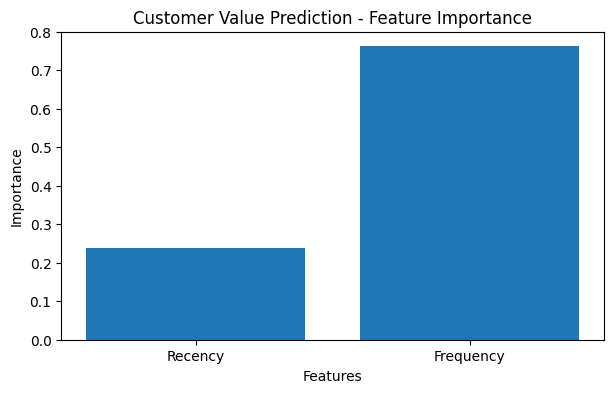

In [31]:
import matplotlib.pyplot as plt

# Feature importance
importance = pd.DataFrame({
    'Features':X.columns,
    'Importance':model.feature_importances_
})
print("Feature Importance:")
print(importance)

# Create graph
plt.figure(figsize=(7,4))
plt.bar(
    importance['Features'],
    importance['Importance']    

)
plt.title("Customer Value Prediction - Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()

In [32]:
import joblib
joblib.dump(model,'customer_value_model.pkl')
print("Model saved successfully!")

Model saved successfully!


In [33]:
! pip install lifetimes

In [34]:
import pandas as pd 
import numpy as np

from lifetimes import BetaGeoFitter

print("BIG/NBD Library Imported Successfully!")

BIG/NBD Library Imported Successfully!


In [35]:
# Find all available DataFrames in notebook
dataframes = {
    name:obj
    for name,obj in globals().items()
    if isinstance(obj,pd.DataFrame)
}
print("Available DataFrames:")

for name,data in dataframes.items():
    print("\nDataFrame Name:",name)
    print("Shape:",data.shape)
    print("Columns:",list(data.columns))

Available DataFrames:

DataFrame Name: _
Shape: (5, 7)
Columns: ['Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score']

DataFrame Name: __
Shape: (5, 3)
Columns: ['Recency', 'Frequency', 'Monetary']

DataFrame Name: ___
Shape: (5, 9)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalAmount']

DataFrame Name: onvoice_data
Shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

DataFrame Name: invoice_data
Shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

DataFrame Name: df
Shape: (392692, 9)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalAmount']

DataFrame Name: _15
Shape: (5, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceD

In [36]:
# Step 1: Prepare transaction data for BG/NBD

import pandas as pd
import numpy as np

# Make a copy of original dataset
transactions = df.copy()

# Check required columns
required_columns = [
    'CustomerID',
    'InvoiceNo',
    'InvoiceDate',
    'Quantity',
    'UnitPrice'
]

print("Required columns available:")
print([col for col in required_columns if col in transactions.columns])

# Remove missing customer IDs
transactions = transactions.dropna(
    subset=required_columns
)

# Convert date into datetime format
transactions['InvoiceDate'] = pd.to_datetime(
    transactions['InvoiceDate']
)

# Remove cancelled invoices
transactions = transactions[
    ~transactions['InvoiceNo'].astype(str).str.startswith('C')
]

# Remove negative and zero purchases
transactions = transactions[
    (transactions['Quantity'] > 0) &
    (transactions['UnitPrice'] > 0)
]

# Calculate transaction amount
transactions['TotalPrice'] = (
    transactions['Quantity'] *
    transactions['UnitPrice']
)

# Create invoice-level data
invoice_data = transactions.groupby(
    ['CustomerID', 'InvoiceNo', 'InvoiceDate'],
    as_index=False
)['TotalPrice'].sum()

print("\nData Cleaning Completed!")
print("Total Invoice Transactions:", len(invoice_data))
print("Unique Customers:", invoice_data['CustomerID'].nunique())

print("\nDataset Preview:")
print(invoice_data.head())

Required columns available:
['CustomerID', 'InvoiceNo', 'InvoiceDate', 'Quantity', 'UnitPrice']

Data Cleaning Completed!
Total Invoice Transactions: 18562
Unique Customers: 4338

Dataset Preview:
   CustomerID InvoiceNo         InvoiceDate  TotalPrice
0     12346.0    541431 2011-01-18 10:01:00    77183.60
1     12347.0    537626 2010-12-07 14:57:00      711.79
2     12347.0    542237 2011-01-26 14:30:00      475.39
3     12347.0    549222 2011-04-07 10:43:00      636.25
4     12347.0    556201 2011-06-09 13:01:00      382.52


In [37]:
import sys 
import lifetimes
print("Python Location:")
print(sys.executable)
print("\nLifetimes Package Location:")
print(lifetimes.__file__)
print("\nLifetimes VErsion:")
print(getattr(lifetimes,"__version__","version not available"))
print("\nPackage Contents:")
print(dir(lifetimes))

Python Location:
/opt/anaconda3/bin/python

Lifetimes Package Location:
/opt/anaconda3/lib/python3.13/site-packages/lifetimes/__init__.py

Lifetimes VErsion:
0.11.3

Package Contents:
['BaseFitter', 'BetaGeoBetaBinomFitter', 'BetaGeoFitter', 'GammaGammaFitter', 'ModifiedBetaGeoFitter', 'ParetoNBDFitter', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '__version__', 'fitters', 'generate_data', 'utils', 'version']


In [38]:
! pip install --upgrade lifetimes

In [39]:
from lifetimes import BetaGeoFitter,GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data


print("Lifetimes library imported successfully!")

Lifetimes library imported successfully!


In [40]:
# Observation period end date
observation_end = invoice_data['InvoiceDate'].max()

#Create customer purchase summary
summary = summary_data_from_transaction_data(invoice_data,
                                              customer_id_col='CustomerID',
                                              datetime_col='InvoiceDate',
                                              monetary_value_col='TotalPrice',
                                              observation_period_end=observation_end,
                                              freq='D'
                                            )
print("Customer Purchase Summary Created!")
print("\nFirst 10 Customers:")
print(summary.head(10))
print("\nSummary Information:")
print(summary.describe())
        
                                             


Customer Purchase Summary Created!

First 10 Customers:
            frequency  recency      T  monetary_value
CustomerID                                           
12346.0           0.0      0.0  325.0        0.000000
12347.0           6.0    365.0  367.0      599.701667
12348.0           3.0    283.0  358.0      301.480000
12349.0           0.0      0.0   18.0        0.000000
12350.0           0.0      0.0  310.0        0.000000
12352.0           6.0    260.0  296.0      368.256667
12353.0           0.0      0.0  204.0        0.000000
12354.0           0.0      0.0  232.0        0.000000
12355.0           0.0      0.0  214.0        0.000000
12356.0           2.0    303.0  325.0      269.905000

Summary Information:
         frequency      recency            T  monetary_value
count  4338.000000  4338.000000  4338.000000     4338.000000
mean      2.864223   130.771554   222.831028      306.049272
std       5.949000   132.210509   117.854570     2612.653650
min       0.000000     0.00000

In [41]:
import pandas as pd
invoice_data = pd.read_excel('/Users/kajalverma/Online Retail.xlsx')
print(invoice_data.head())
print("Dataset Shape:",invoice_data.shape)

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
Dataset Shape: (541909, 8)


In [42]:
!pip install openpyxl

In [44]:
print("Column Names:")
print(invoice_data.columns.tolist())
print("\nDataset Information:")
print(invoice_data.info())
print("\nMissing Values:")
print(invoice_data.isnull().sum())

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
None

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID 

In [48]:
# Remove rows with missing CustomerID
invoice_data = invoice_data.dropna(subset=['CustomerID'])
# Remove cancelled and invalid transactions
invoice_data = invoice_data[
    (invoice_data['Quantity']>0)&
    (invoice_data['UnitPrice']>0)&
    (~invoice_data['InvoiceNo'].astype(str).str.startswith('C'))
    ]
# Convert CustomerID to integer
invoice_data['CustomerID'] = invoice_data['CustomerID'].astype(int)

print("Data Cleaning Completed!")
print("Remaining Rows:",invoice_data.shape[0])
print("Missing Values:")
print(invoice_data.isnull().sum())
                                   

Data Cleaning Completed!
Remaining Rows: 397884
Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [49]:
invoice_data['TotalPrice'] = (
    invoice_data['Quantity']*invoice_data['UnitPrice']
)
print(invoice_data[['Quantity','UnitPrice','TotalPrice']].head())

   Quantity  UnitPrice  TotalPrice
0         6       2.55       15.30
1         6       3.39       20.34
2         8       2.75       22.00
3         6       3.39       20.34
4         6       3.39       20.34


In [51]:
from lifetimes.utils import summary_data_from_transaction_data
observation_end = invoice_data['InvoiceDate'].max()
summary = summary_data_from_transaction_data(invoice_data,
                                             customer_id_col='CustomerID',
                                             datetime_col='InvoiceDate',
                                             monetary_value_col='TotalPrice',
                                             observation_period_end=observation_end,
                                             freq='D'
                                            )
print("Customer Purchase Summary Created!")
print("\nFirst 10 Customer:")
print(summary.head(10))
print("\nSummary Information:")
print(summary.describe())

Customer Purchase Summary Created!

First 10 Customer:
            frequency  recency      T  monetary_value
CustomerID                                           
12346             0.0      0.0  325.0        0.000000
12347             6.0    365.0  367.0      599.701667
12348             3.0    283.0  358.0      301.480000
12349             0.0      0.0   18.0        0.000000
12350             0.0      0.0  310.0        0.000000
12352             6.0    260.0  296.0      368.256667
12353             0.0      0.0  204.0        0.000000
12354             0.0      0.0  232.0        0.000000
12355             0.0      0.0  214.0        0.000000
12356             2.0    303.0  325.0      269.905000

Summary Information:
         frequency      recency            T  monetary_value
count  4338.000000  4338.000000  4338.000000     4338.000000
mean      2.864223   130.771554   222.831028      307.028848
std       5.949000   132.210509   117.854570     2612.749850
min       0.000000     0.000000

In [55]:
# Convert days to weeks (or divide by 30 for months)
summary['recency_w'] = summary['recency'] / 7.0
summary['T_w'] = summary['T'] / 7.0

bgf = BetaGeoFitter(penalizer_coef=0.1)
bgf.fit(summary['frequency'], summary['recency_w'], summary['T_w'])

<lifetimes.BetaGeoFitter: fitted with 4338 subjects, a: 0.00, alpha: 7.06, b: 0.00, r: 0.59>

In [59]:
# Predict purchases for next 30 days

summary['predicted_purchases'] = (
    bgf.conditional_expected_number_of_purchases_up_to_time(
        30/7,
        summary['frequency'],
        summary['recency_w'],
        summary['T_w']
    )
)

print("Purchase Prediction Completed!")

print(
    summary[
        ['frequency', 'recency_w', 'T_w', 'predicted_purchases']
    ].head(10)
)

Purchase Prediction Completed!
            frequency  recency_w        T_w  predicted_purchases
CustomerID                                                      
12346             0.0   0.000000  46.428571             0.047563
12347             6.0  52.142857  52.428571             0.475019
12348             3.0  40.428571  51.142857             0.264611
12349             0.0   0.000000   2.571429             0.264134
12350             0.0   0.000000  44.285714             0.049548
12352             6.0  37.142857  42.285714             0.572656
12353             0.0   0.000000  29.142857             0.070273
12354             0.0   0.000000  33.142857             0.063281
12355             0.0   0.000000  30.571429             0.067605
12356             2.0  43.285714  46.428571             0.207810


In [60]:
from lifetimes import GammaGammaFitter
# Select customers who made repeat purchases
returning_customers = summary[
    (summary['frequency']>0)&
    (summary['monetary_value']>0)
    ]
# Fit Gamma-Gamma Model
ggf = GammaGammaFitter(penalizer_coef=0.001)
ggf.fit(
    returning_customers['frequency'],
    returning_customers['monetary_value']
)
# Predict average profit
returning_customers['expected_average_profit']=(
    ggf.conditional_expected_average_profit(
        returning_customers['frequency'],
        returning_customers['monetary_value']
    )
)
print("Expected Average Profit Calculator!")
print(returning_customers[
    ['frequency','monetary_value','expected_average_profit']
    ].head(10))    
    

Expected Average Profit Calculator!
            frequency  monetary_value  expected_average_profit
CustomerID                                                    
12347             6.0      599.701667               603.040247
12348             3.0      301.480000               306.725889
12352             6.0      368.256667               371.034926
12356             2.0      269.905000               277.562534
12358             1.0      683.200000               704.704679
12359             3.0     1941.693333              1954.900317
12360             2.0      789.240000               800.687773
12362             9.0      527.458889               529.566310
12363             1.0      252.900000               268.077625
12364             3.0      229.726667               234.624287


In [62]:
# Calculate Customer Lifetime Value
clv = ggf.customer_lifetime_value(
    bgf,
    returning_customers['frequency'],
    returning_customers['recency_w'],
    returning_customers['T_w'],
    returning_customers['monetary_value'],
    time=52,
    freq='W',
    discount_rate=0.01
)
returning_customers['CLV']=clv
print("Customer Lifetime Value Calculation!")
print(returning_customers[['CLV']].head(10))

Customer Lifetime Value Calculation!
                     CLV
CustomerID              
12347       11731.201882
12348        3323.871298
12352        8701.506922
12356        2362.174409
12358        6918.696979
12359       22688.049593
12360       10229.169221
12362       18122.481904
12363        1801.063839
12364        6417.220217


In [63]:
import numpy as np
# Calculate CLV thresholds
high_threshold = returning_customers['CLV'].quantile(0.75)
medium_threshold = returning_customers['CLV'].quantile(0.50)
# Create customer segments
returning_customers['Customer_Segment'] = np.select(
    [
        returning_customers['CLV']>=high_threshold,
        returning_customers['CLV']>=medium_threshold
    ],
    [
        'High Value',
        'Medium Value',
    ],
    default = 'Low Value'
)
print(returning_customers[
    ['CLV','Customer_Segment']
    ].head(10))
print("\nCustomer Segment Count:")
print(returning_customers['Customer_Segment'].value_counts())

                     CLV Customer_Segment
CustomerID                               
12347       11731.201882       High Value
12348        3323.871298        Low Value
12352        8701.506922     Medium Value
12356        2362.174409        Low Value
12358        6918.696979     Medium Value
12359       22688.049593       High Value
12360       10229.169221       High Value
12362       18122.481904       High Value
12363        1801.063839        Low Value
12364        6417.220217     Medium Value

Customer Segment Count:
Customer_Segment
Low Value       1395
High Value       698
Medium Value     697
Name: count, dtype: int64


In [64]:
# Save final customer analysis
returning_customers.to_csv(
    'Customer_Lifetime_Value_Results.csv'
)
print("Final Results Saved Successfully!")

Final Results Saved Successfully!


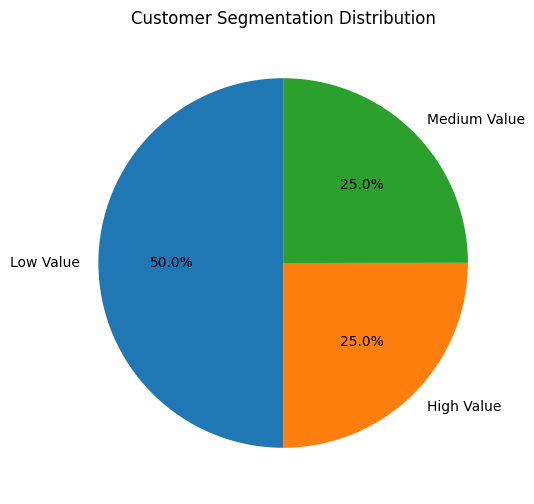

In [66]:
import matplotlib.pyplot as plt
# Customer segment distribution
segment_counts = returning_customers['Customer_Segment'].value_counts()

plt.figure(figsize=(8,6))
plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Customer Segmentation Distribution')
plt.show()

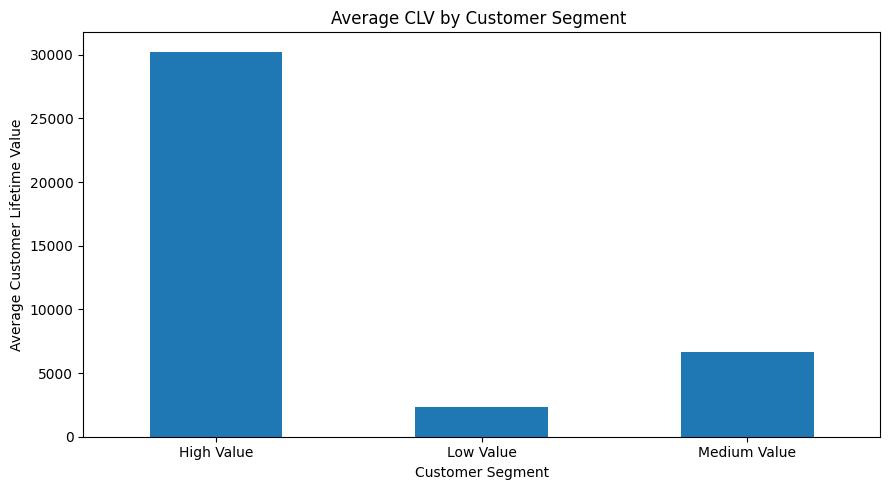

In [67]:
# Average CLV Customer Segment
avg_clv = returning_customers.groupby(
    'Customer_Segment'
)['CLV'].mean()
plt.figure(figsize=(9,5))
avg_clv.plot(kind='bar')
plt.title('Average CLV by Customer Segment ')
plt.xlabel('Customer Segment')
plt.ylabel('Average Customer Lifetime Value')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [68]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_excel("Online Retail.xlsx")

# Convert dates
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Remove missing customer IDs
df = df.dropna(subset=["CustomerID"])

# Remove cancelled invoices and invalid transactions
df = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Calculate revenue
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Set observation date and prediction period
snapshot_date = df["InvoiceDate"].max() - pd.Timedelta(days=90)
end_date = snapshot_date + pd.Timedelta(days=90)

# Historical transactions
history = df[df["InvoiceDate"] < snapshot_date].copy()

# Future transactions
future = df[
    (df["InvoiceDate"] >= snapshot_date) &
    (df["InvoiceDate"] < end_date)
].copy()

# RFM-T features
rfm_t = history.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x:
             (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    Tenure=("InvoiceDate", lambda x:
            (snapshot_date - x.min()).days),
    Total_Quantity=("Quantity", "sum"),
    Unique_Products=("StockCode", "nunique")
).reset_index()

# Average order value
rfm_t["Average_Order_Value"] = (
    rfm_t["Monetary"] / rfm_t["Frequency"]
)

# Future 90-day revenue target
future_revenue = future.groupby("CustomerID")["Revenue"].sum()

rfm_t["Future_Revenue_90D"] = (
    rfm_t["CustomerID"].map(future_revenue).fillna(0)
)

print("RFM-T Feature Engineering Completed!")
print(rfm_t.head())
print(rfm_t.shape)

RFM-T Feature Engineering Completed!
   CustomerID  Recency  Frequency  Monetary  Tenure  Total_Quantity  \
0     12346.0      235          1  77183.60     235           74215   
1     12347.0       39          5   2790.86     276            1590   
2     12348.0      158          3   1487.24     267            2124   
3     12350.0      219          1    334.40     219             197   
4     12352.0      171          5   1561.81     206             254   

   Unique_Products  Average_Order_Value  Future_Revenue_90D  
0                1         77183.600000                0.00  
1               82           558.172000             1519.14  
2               22           495.746667              310.00  
3               17           334.400000                0.00  
4               26           312.362000              944.23  
(3370, 9)


In [69]:
rfm_t.to_csv("rfm_t_features.csv",index=False)
print("RFM-T dataset saved successfully!")

RFM-T dataset saved successfully!


In [73]:
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split

# Select input features
features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Tenure",
    "Total_Quantity",
    "Unique_Products",
    "Average_Order_Value"
]

X = rfm_t[features]
y = rfm_t["Future_Revenue_90D"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42
)

xgb_model.fit(X_train, y_train)

# Predictions
y_pred = xgb_model.predict(X_test)

print("XGBoost Model Trained Successfully!")

XGBoost Model Trained Successfully!


In [74]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("----------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MODEL EVALUATION
----------------------
MAE: 967.9632827478983
RMSE: 7181.035218992273
R2 Score: 0.20766461226915733


In [75]:
from scipy.stats import spearmanr
correlation, p_value = spearmanr(y_test, y_pred)
print("Spearman Correlation:", correlation)
print("P-value:", p_value)

Spearman Correlation: 0.4760281183652492
P-value: 2.0491179804419056e-39


          Predicted       Actual
Decile                          
10      6509.206055  5063.382059
9        949.360291  1014.662090
8        666.525330   784.496269
7        451.890533   477.980294
6        328.932709   367.697164
5        265.553864   248.023881
4        214.760086   278.127794
3        158.232376   161.149851
2        120.713882   166.481045
1         59.111717  2644.275882


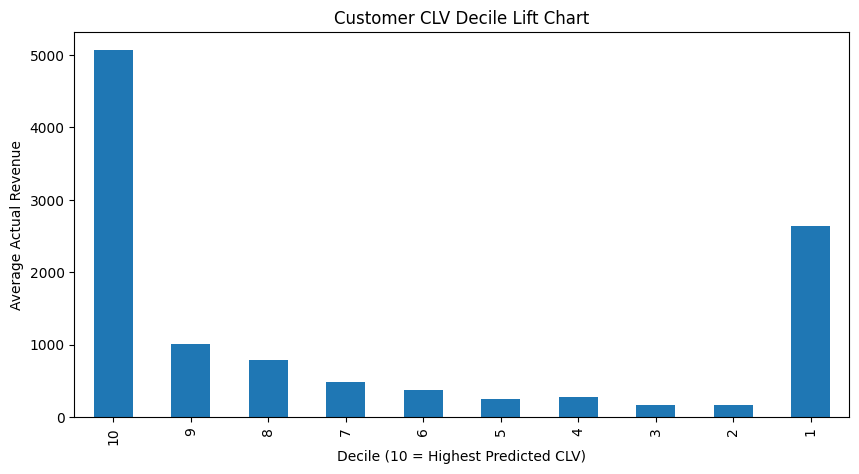

In [77]:
import matplotlib.pyplot as plt
import pandas as pd
results = pd.DataFrame({
    "Actual_Revenue": y_test.values,
    "Predicted_Revenue": y_pred
})
results["Decile"] = pd.qcut(
    results["Predicted_Revenue"].rank(method="first"),
    10,
    labels=False
) + 1
decile_results = results.groupby("Decile").agg(
    Predicted=("Predicted_Revenue","mean"),
    Actual=("Actual_Revenue","mean")
).sort_values("Decile",ascending=False)

print(decile_results)
decile_results["Actual"].plot(
    kind="bar",
    figsize=(10,5),
    title="Customer CLV Decile Lift Chart"
)
plt.xlabel("Decile (10 = Highest Predicted CLV)")
plt.ylabel("Average Actual Revenue")
plt.show()

In [79]:
prediction_output = pd.DataFrame({
    "CustomerID": rfm_t.loc[
        X_test.index, "CustomerID"
        ].values,
    "Actual_Revenue_90D": y_test.values,
    "Predicted_Revenue_90D":y_pred
})
prediction_output.to_csv(
    "xgboost_clv_predictions.csv",
    index=False
)
print("Predictions saved successfully!")
prediction_output.head()

Predictions saved successfully!


,CustomerID,Actual_Revenue_90D,Predicted_Revenue_90D
0,17980.0,0.00,658.416382
1,17643.0,0.00,58.034241
2,16968.0,186.12,214.599426
3,12573.0,0.00,143.110046
4,16985.0,1885.58,1508.247192


In [80]:
import joblib
joblib.dump(xgb_model,"xgboost_clv_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [82]:
# Predict 90-day revenue for all customers
rfm_t["XGBoost_CLV_90D"] = np.maximum(
    xgb_model.predict(rfm_t[features]),0
)
rfm_t["Final_CLV"] = rfm_t["XGBoost_CLV_90D"]
print("Final CLV calculated!")
rfm_t[["CustomerID", "XGBoost_CLV_90D", "Final_CLV"]].head()

Final CLV calculated!


,CustomerID,XGBoost_CLV_90D,Final_CLV
0,12346.0,379.230896,379.230896
1,12347.0,1117.985840,1117.985840
2,12348.0,659.500671,659.500671
3,12350.0,175.198212,175.198212
4,12352.0,528.228760,528.228760


In [83]:
rfm_t["CLV_Segment"] = pd.qcut(
    rfm_t["Final_CLV"].rank(method="first"),
    q=3,
    labels=["Low Value", "Medium Value", "High Value"]
)
print(rfm_t["CLV_Segment"].value_counts())

CLV_Segment
High Value      1124
Low Value       1123
Medium Value    1123
Name: count, dtype: int64


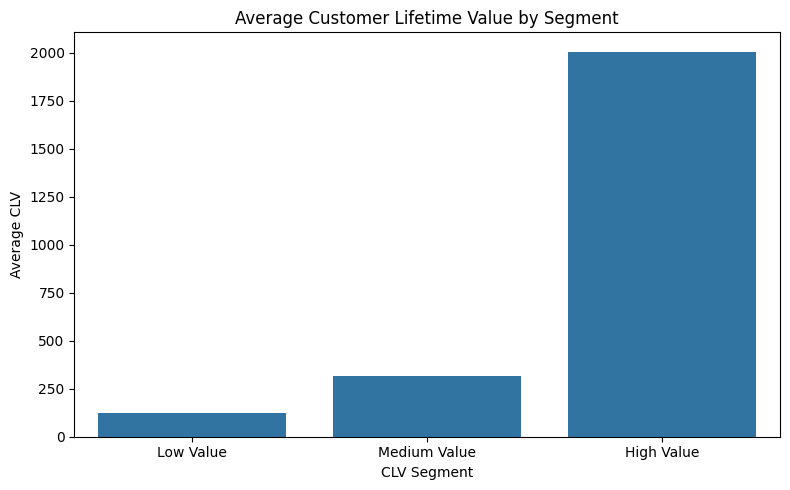

In [84]:
import matplotlib.pyplot as plt 
import seaborn as sns
segment_clv = rfm_t.groupby(
    "CLV_Segment",observed=False
)["Final_CLV"].mean().reset_index()
plt.figure(figsize=(8,5))

sns.barplot(
    data=segment_clv,
    x="CLV_Segment",
    y="Final_CLV"
)
plt.title("Average Customer Lifetime Value by Segment")
plt.xlabel("CLV Segment")
plt.ylabel("Average CLV")
plt.tight_layout()
plt.show()

In [85]:
rfm_t.to_csv("final_customer_clv.csv", index=False)

print("Final CSV exported successfully!")

Final CSV exported successfully!


In [86]:
json_output = rfm_t[
    ["CustomerID","Final_CLV", "CLV_Segment"]
    ].copy()
json_output["CLV_Segment"] = json_output["CLV_Segment"].astype(str)

json_output.to_json(
    "final_customer_clv.json",
    orient="records",
    indent=4
)
print("JSON file exported successfully!")






JSON file exported successfully!


In [87]:
import os 
print("PROJECT OUTPUT FILES")

for file in os.listdir():
    if file.endswith((".csv",".json",".pkl")):
        print("✔", file)

PROJECT OUTPUT FILES
✔ xgboost_clv_model.pkl
✔ final_customer_clv.csv
✔ rfm_t_features.csv
✔ final_customer_clv.json
✔ Customer_Lifetime_Value_Results.csv
✔ xgboost_clv_predictions.csv
✔ customer_value_model.pkl
✔ cleaned_usc_data.csv


In [1]:
import os
import shutil

project_folder = os.path.expanduser("~/Desktop/CLV_Project")

files_to_copy = [
    "xgboost_clv_model.pkl",
    "rfm_t_features.csv",
    "final_customer_clv.json",
    "Customer_Lifetime_Value_Results.csv",
    "xgboost_clv_predictions.csv",
    "customer_value_model.pkl",
    "cleaned_usc_data.csv"
]

for file in files_to_copy:
    if os.path.exists(file):
        shutil.copy(file, project_folder)
        print("Copied:", file)
    else:
        print("Not found:", file)

Copied: xgboost_clv_model.pkl
Copied: rfm_t_features.csv
Copied: final_customer_clv.json
Copied: Customer_Lifetime_Value_Results.csv
Copied: xgboost_clv_predictions.csv
Copied: customer_value_model.pkl
Copied: cleaned_usc_data.csv


In [2]:
readme_content = """
# Customer Lifetime Value Prediction

## Project Overview
This project predicts Customer Lifetime Value (CLV)
using machine learning techniques.

## Objectives
- Analyze customer purchasing behavior.
- Perform RFM analysis.
- Calculate customer value.
- Predict Customer Lifetime Value using XGBoost.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- XGBoost

## Machine Learning Models
- XGBoost
- Customer Value Model

## Project Outputs
- Customer CLV predictions
- RFM features
- Trained ML models
- Final customer CLV dataset

## Project Files
All generated CSV, JSON and PKL files
are included in this project folder.
"""

with open("README.md", "w") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [3]:
import shutil

shutil.copy(
    "README.md",
    project_folder
)

print("README copied successfully!")

README copied successfully!


In [4]:
requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
xgboost
joblib
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [5]:
import shutil
import os

shutil.copy(
    "requirements.txt",
    project_folder
)

print("requirements.txt copied successfully!")

requirements.txt copied successfully!


In [2]:
import os

project_folder = os.path.expanduser(
    "~/Desktop/CLV_Project"
)

print("PROJECT FOLDER CONTENTS")

for file in os.listdir(project_folder):
    print("✔", file)

PROJECT FOLDER CONTENTS
✔ xgboost_clv_model.pkl
✔ .DS_Store
✔ requirements.txt
✔ rfm_t_features.csv
✔ final_customer_clv.json
✔ Customer_Lifetime_Value_Results.csv
✔ README.md
✔ finalclv.csv
✔ xgboost_clv_predictions.csv
✔ customer_value_model.pkl
✔ cleaned_usc_data.csv
